# Módulo 2: shot charts

**Preguntas:**
- **B.** En toda la liga, ¿qué zona rinde más puntos por tiro? ¿Un tiro largo de media distancia rinde menos que un triple?
- **Un jugador.** ¿Dónde tira y qué tan bien convierte, separando *dónde* de *cómo*?
- **Validación.** ¿Hay que "encoger" los porcentajes por zona hacia el promedio de la liga? ¿Cuánto? (se mide, no se supone)

**Diseño (decidido antes de ver los datos):**
- Puntos por tiro = % de acierto × 2 o 3. No cuenta libres ni jugadas de 2+1.
- Temporada principal 2025-26; estabilidad 2021-22 a 2025-26.
- Los porcentajes por zona se acompañan de un intervalo de Wilson del 95 %.
- Para el encogimiento: dividir las fechas de cada jugador en orden cronológico (1.ª mitad predice 2.ª mitad), nunca mezclar.

**Mi hipótesis previa (B):** ninguna ("sin intuición, corre"). La referencia es "todas las zonas rinden parecido".

Para reproducir: `python -m uv run jupyter lab`. Los datos salen de la caché local.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sportslab.analysis.court import court_lines
from sportslab.analysis.shots import (
    BASIC,
    BASIC_RANGE,
    PRIOR_ATTEMPTS,
    half_season_counts,
    league_zone_table,
    selection_vs_making,
    shrinkage_error,
    zone_table,
)
from sportslab.data import NbaClient
from sportslab.data.games import season_labels
from sportslab.data.players import load_player_stats
from sportslab.data.shots import load_player_shots
from sportslab.models.metrics import wilson_interval

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:.3f}".format

client = NbaClient()
SEASON = "2025-26"
STABILITY = season_labels(2021, 2025)
JOKIC = 203999  # any player works for the league frame; he also is our example shooter

shots, league = load_player_shots(client, JOKIC, SEASON)
print(f"Jokić {SEASON}: {len(shots)} tiros; liga: {int(league['fga'].sum()):,} tiros")

Jokić 2025-26: 1132 tiros; liga: 219,160 tiros


## 0. Un hallazgo de datos antes de empezar

`ShotChartDetail` devuelve dos tablas: los tiros del jugador y los totales de la **liga completa** por zona. Esa segunda tabla es **idéntica para todos los jugadores** de una temporada (lo comprobé con dos jugadores distintos: ~219 000 tiros). Dos consecuencias:

1. La pregunta B no necesita 500 peticiones: una sola por temporada da la liga entera.
2. Con `team_id=0` el endpoint devuelve todos los tiros del jugador aunque haya cambiado de equipo en la temporada.

## 1. Hipótesis B: puntos por tiro por zona, en toda la liga

                         fga    fgm  fg_pct  share  value   pps
zone_basic                                                     
Restricted Area        62253  41768   0.671  0.284      2 1.342
Left Corner 3          12210   4729   0.387  0.056      3 1.162
Right Corner 3         11360   4386   0.386  0.052      3 1.158
Above the Break 3      67375  23585   0.350  0.307      3 1.050
In The Paint (Non-RA)  43908  19565   0.446  0.200      2 0.891
Mid-Range              22025   9179   0.417  0.101      2 0.834


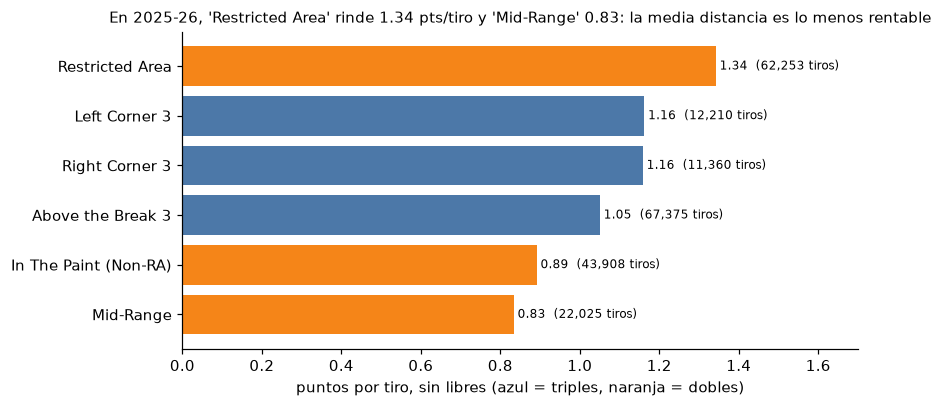

In [2]:
leagues = {s: load_player_shots(client, JOKIC, s)[1] for s in STABILITY}
lg = league_zone_table(leagues[SEASON], BASIC).sort_values("pps", ascending=False)
print(lg.to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
colors = ["#4C78A8" if v == 3 else "#F58518" for v in lg["value"]]
ax.barh(lg.index, lg["pps"], color=colors)
ax.invert_yaxis()
for y, (pps, fga) in enumerate(zip(lg["pps"], lg["fga"], strict=True)):
    ax.text(pps + 0.01, y, f"{pps:.2f}  ({fga:,} tiros)", va="center", fontsize=8)
ax.set_xlim(0, 1.7)
ax.set_xlabel("puntos por tiro, sin libres (azul = triples, naranja = dobles)")
ax.set_title(
    f"En {SEASON}, '{lg.index[0]}' rinde {lg['pps'].iloc[0]:.2f} pts/tiro y '{lg.index[-1]}' "
    f"{lg['pps'].iloc[-1]:.2f}: la media distancia es lo menos rentable",
    fontsize=10,
)
plt.tight_layout()
plt.show()

In [3]:
fine = league_zone_table(leagues[SEASON], BASIC_RANGE).sort_values("pps", ascending=False)
print(fine[fine["fga"] > 1000].to_string())

                                         fga    fgm  fg_pct  share  value   pps
zone_basic            zone_range                                               
Restricted Area       Less Than 8 ft.  62253  41768   0.671  0.284      2 1.342
Left Corner 3         24+ ft.          12210   4729   0.387  0.056      3 1.162
Right Corner 3        24+ ft.          11360   4386   0.386  0.052      3 1.158
Above the Break 3     24+ ft.          67366  23579   0.350  0.307      3 1.050
In The Paint (Non-RA) 8-16 ft.         18313   8312   0.454  0.084      2 0.908
                      Less Than 8 ft.  25595  11253   0.440  0.117      2 0.879
Mid-Range             8-16 ft.         11270   4869   0.432  0.051      2 0.864
                      16-24 ft.        10755   4310   0.401  0.049      2 0.801


### ¿Un tiro largo de media distancia (16-24 ft) rinde menos que un triple?

La diferencia hay que medirla contra el ruido: con ~10 000 tiros en la zona, un intervalo de Wilson sobre el % de acierto es de unos ±1 punto porcentual, es decir ±0.02 puntos por tiro. Y se pregunta si se sostiene en cinco temporadas.

         mid 16-24 ft  mid IC bajo  mid IC alto  triple arriba del arco  triple esquina izq.  triple esquina der.
2021-22         0.799        0.783        0.814                   1.038                1.153                1.146
2022-23         0.828        0.812        0.845                   1.064                1.155                1.156
2023-24         0.813        0.796        0.831                   1.079                1.158                1.181
2024-25         0.798        0.779        0.817                   1.060                1.158                1.170
2025-26         0.801        0.783        0.820                   1.050                1.162                1.158


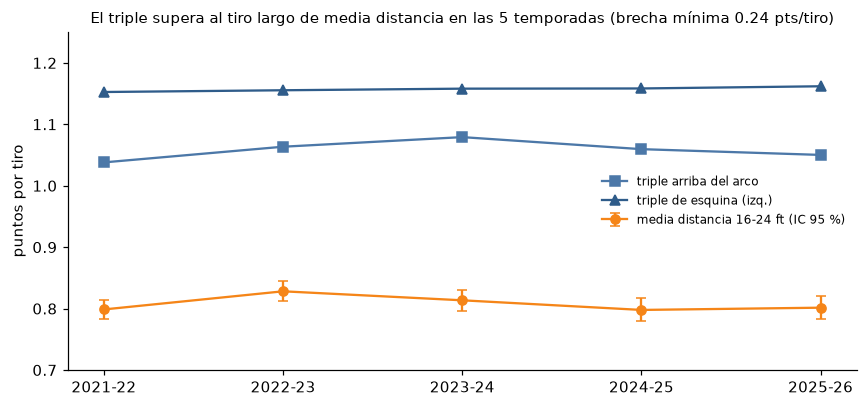

In [4]:
rows = {}
for s, frame in leagues.items():
    f = league_zone_table(frame, BASIC_RANGE)
    b = league_zone_table(frame, BASIC)
    mid = f.loc[("Mid-Range", "16-24 ft.")]
    low, high = wilson_interval(mid["fgm"], mid["fga"])
    rows[s] = {
        "mid 16-24 ft": mid["pps"],
        "mid IC bajo": low * 2,
        "mid IC alto": high * 2,
        "triple arriba del arco": b.loc["Above the Break 3", "pps"],
        "triple esquina izq.": b.loc["Left Corner 3", "pps"],
        "triple esquina der.": b.loc["Right Corner 3", "pps"],
    }
table = pd.DataFrame(rows).T
print(table.to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(table))
ax.errorbar(
    x,
    table["mid 16-24 ft"],
    yerr=[
        table["mid 16-24 ft"] - table["mid IC bajo"],
        table["mid IC alto"] - table["mid 16-24 ft"],
    ],
    marker="o",
    color="#F58518",
    capsize=3,
    label="media distancia 16-24 ft (IC 95 %)",
)
ax.plot(
    x, table["triple arriba del arco"], marker="s", color="#4C78A8", label="triple arriba del arco"
)
ax.plot(
    x, table["triple esquina izq."], marker="^", color="#2F5C8A", label="triple de esquina (izq.)"
)
ax.set_xticks(x, table.index)
ax.set_ylim(0.7, 1.25)
ax.set_ylabel("puntos por tiro")
gap = (table["triple arriba del arco"] - table["mid 16-24 ft"]).min()
ax.set_title(
    f"El triple supera al tiro largo de media distancia en las 5 temporadas "
    f"(brecha mínima {gap:.2f} pts/tiro)",
    fontsize=10,
)
ax.legend(frameon=False, fontsize=8, loc="center right")
plt.tight_layout()
plt.show()

**Lectura de B.** Orden de rentabilidad en 2025-26: área restringida (~1.34) > triples de esquina (~1.16) > triple arriba del arco (~1.05) > pintura fuera del área restringida (~0.89) > media distancia (~0.83). El tiro largo de media distancia (16-24 ft) rinde ~0.80, unos 0.25 puntos menos que un triple arriba del arco; la brecha es mucho mayor que el ruido de muestreo y se repite en las cinco temporadas. El orden entre zonas es casi idéntico cada año.

**Lo que esto NO dice:**
- No dice que "si todos tiraran más desde el aro, la liga anotaría más": el área restringida es donde caen los layups y mates abiertos, y no todos pueden tirar desde ahí cuando quieran.
- Muchos tiros de media distancia son de fin de reloj o contra defensa; la zona no distingue tiros abiertos de contestados.
- No cuenta libres: las faltas cobradas cerca del aro hacen esa zona aún más valiosa.

## 2. Un jugador: el mapa y las zonas

El mapa muestra *dónde*; la tabla por zona con intervalo muestra *qué tan bien* y con cuánta certeza.

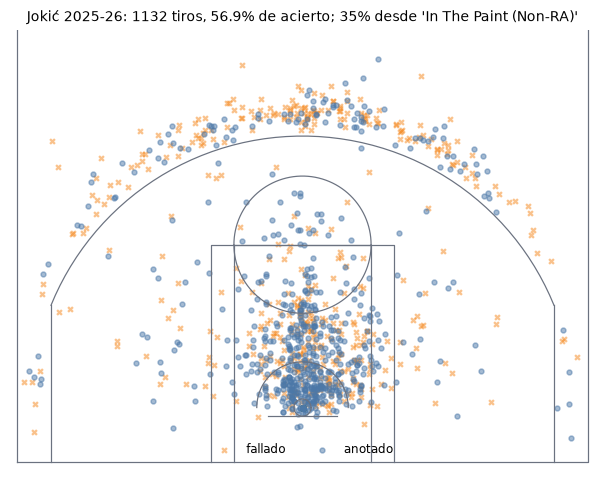

In [5]:
fig, ax = plt.subplots(figsize=(5.6, 5.4))
for x, y in court_lines().values():
    ax.plot(x, y, color="#6B7280", lw=0.8)
missed, made = shots[shots["made"] == 0], shots[shots["made"] == 1]
ax.scatter(missed["x"], missed["y"], s=10, marker="x", color="#F58518", alpha=0.5, label="fallado")
ax.scatter(made["x"], made["y"], s=10, color="#4C78A8", alpha=0.5, label="anotado")
ax.set_xlim(-255, 255)
ax.set_ylim(-52, 330)
ax.set_aspect("equal")
ax.axis("off")
t = zone_table(shots, league)
top = t.sort_values("freq", ascending=False).iloc[0]
ax.set_title(
    f"Jokić {SEASON}: {len(shots)} tiros, {shots['made'].mean():.1%} de acierto; "
    f"{top['freq']:.0%} desde '{top.name}'",
    fontsize=9,
)
ax.legend(frameon=False, loc="lower center", ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

In [6]:
t = zone_table(shots, league, BASIC)
print(
    t[
        [
            "fga",
            "fg_pct",
            "ci_low",
            "ci_high",
            "league_fg_pct",
            "shrunk_fg_pct",
            "pps",
            "league_pps",
            "excludes_league",
        ]
    ].to_string()
)
split = selection_vs_making(shots, league, BASIC)
print()
print({k: round(float(v), 3) for k, v in split.items()})

                       fga  fg_pct  ci_low  ci_high  league_fg_pct  shrunk_fg_pct   pps  league_pps  excludes_league
zone_basic                                                                                                          
Above the Break 3      277   0.368   0.314    0.426          0.350          0.363 1.105       1.050            False
In The Paint (Non-RA)  394   0.576   0.527    0.624          0.446          0.550 1.152       0.891             True
Left Corner 3           10   0.500   0.237    0.763          0.387          0.398 1.500       1.162            False
Mid-Range              118   0.559   0.469    0.646          0.417          0.494 1.119       0.834             True
Restricted Area        325   0.735   0.685    0.780          0.671          0.720 1.471       1.342             True
Right Corner 3           8   0.625   0.306    0.863          0.386          0.404 1.875       1.158            False

{'n': 1132.0, 'league_pps': 1.091, 'selection': -0.033, 'making

Fíjate en las esquinas: con 10 y 8 tiros, un 50 % y un 62 % tienen intervalos enormes (la liga cae dentro). En esas zonas el porcentaje crudo casi no informa. Para eso está el siguiente experimento.

**Dónde vs. cómo.** Jokić gana muy poco por *dónde* tira (su mezcla de zonas rinde ~0.03 pts/tiro menos que la media si convirtiera como la liga) y bastante por *cómo* convierte (+0.18, intervalo que excluye 0). Dos advertencias: es un jugador elegido por mí entre los de mayor PIE (selección de un caso extremo), y las zonas no distinguen tiros abiertos de contestados.

## 3. ¿Hay que encoger los porcentajes por zona?

Un porcentaje por zona con pocos tiros es en gran parte ruido. La idea del *encogimiento* es acercarlo al promedio de la liga:

`ajustado = (anotados + k · %liga) / (tiros + k)`

¿Cuánto vale k? No se asume: se mide. Para los 100 jugadores con más minutos de 2025-26, uso la **1.ª mitad de sus fechas** para predecir su % por zona en la **2.ª mitad** (orden cronológico, sin mezclar), con distintos k. El error se pondera por los tiros de la 2.ª mitad.

100 jugadores, 590 jugador-zona, 45,738 tiros en la 1.ª mitad
0         0.00650
5         0.00550
10        0.00508
20        0.00463
40        0.00424
80        0.00398
160       0.00393
320       0.00404
1000000   0.00470


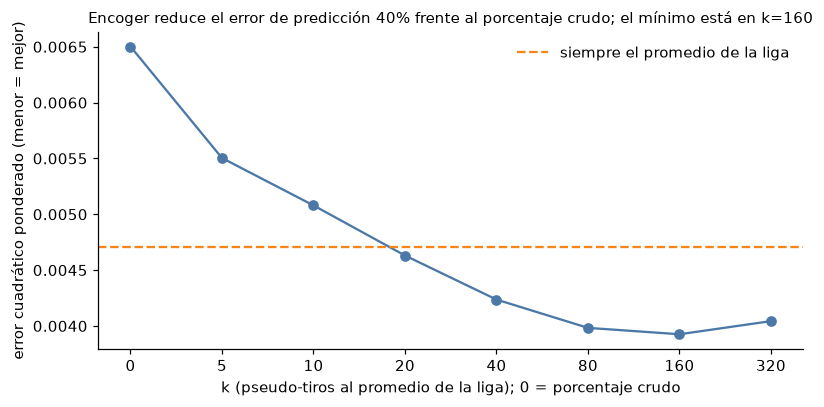

In [7]:
PRIORS = (0, 5, 10, 20, 40, 80, 160, 320, 1_000_000)
pd.options.display.float_format = "{:.5f}".format  # errors differ in the 4th decimal
top100 = load_player_stats(client, [SEASON]).nlargest(100, "minutes")
frames = []
for pid in top100["player_id"]:
    s, lgue = load_player_shots(client, int(pid), SEASON)
    c = half_season_counts(s, BASIC).reset_index()
    c["player_id"] = pid
    frames.append(c)
counts = pd.concat(frames, ignore_index=True)
counts["league_rate"] = counts["zone_basic"].map(league_zone_table(lgue, BASIC)["fg_pct"])

err = pd.Series({k: shrinkage_error(counts, k) for k in PRIORS})
league_only = err.iloc[-1]
finite = err.iloc[:-1]
best_k = int(finite.idxmin())
print(
    f"{len(top100)} jugadores, {len(counts)} jugador-zona, {int(counts['fga_1'].sum()):,} tiros en la 1.ª mitad"
)
print(err.rename("error ponderado").to_string())

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(range(len(finite)), finite.values, marker="o", color="#4C78A8")
ax.axhline(league_only, color="#F58518", ls="--", label="siempre el promedio de la liga")
ax.set_xticks(range(len(finite)), [str(k) for k in finite.index])
ax.set_xlabel("k (pseudo-tiros al promedio de la liga); 0 = porcentaje crudo")
ax.set_ylabel("error cuadrático ponderado (menor = mejor)")
ax.set_title(
    f"Encoger reduce el error de predicción {1 - finite.min() / finite.iloc[0]:.0%} "
    f"frente al porcentaje crudo; el mínimo está en k={best_k}",
    fontsize=10,
)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [8]:
by_zone = pd.DataFrame(
    {z: {k: shrinkage_error(part, k) for k in PRIORS} for z, part in counts.groupby("zone_basic")}
).T
by_zone.columns = [f"k={k}" if k < 1_000_000 else "liga" for k in PRIORS]
print(by_zone.to_string())
print("Mejor k por zona:", by_zone.idxmin(axis=1).to_dict())
print("Valor por defecto del proyecto:", PRIOR_ATTEMPTS)

                          k=0     k=5    k=10    k=20    k=40    k=80   k=160   k=320    liga
Above the Break 3     0.00291 0.00277 0.00268 0.00255 0.00239 0.00222 0.00211 0.00208 0.00229
In The Paint (Non-RA) 0.00519 0.00482 0.00455 0.00418 0.00379 0.00355 0.00361 0.00394 0.00532
Left Corner 3         0.02581 0.01842 0.01646 0.01491 0.01394 0.01350 0.01339 0.01342 0.01355
Mid-Range             0.01073 0.00834 0.00737 0.00646 0.00579 0.00548 0.00552 0.00576 0.00661
Restricted Area       0.00399 0.00376 0.00357 0.00331 0.00299 0.00273 0.00262 0.00269 0.00337
Right Corner 3        0.02195 0.01764 0.01574 0.01398 0.01278 0.01225 0.01214 0.01219 0.01237
Mejor k por zona: {'Above the Break 3': 'k=320', 'In The Paint (Non-RA)': 'k=80', 'Left Corner 3': 'k=160', 'Mid-Range': 'k=80', 'Restricted Area': 'k=160', 'Right Corner 3': 'k=160'}
Valor por defecto del proyecto: 100


**Lectura.** El porcentaje crudo es el peor predictor: es peor incluso que ignorar al jugador y usar siempre el promedio de la liga. Eso significa que, con medio año de tiros, las diferencias *entre jugadores* en un mismo tipo de zona son en su mayoría ruido de muestreo; algo real hay (el mínimo está en k≈160, no en "liga" pura), pero poco. Mi convención inicial (k=20) estaba claramente corta: el error es plano entre k=80 y k=320, así que el valor por defecto pasó a **100**.

**Cautelas:**
- Solo 100 jugadores de mucha minutería (590 jugador-zona); los jugadores de poco volumen no están en el análisis.
- Una sola temporada y un solo corte (mitad y mitad).
- k óptimo por zona va de 80 a 320, con diferencias pequeñas entre valores cercanos; no sobreinterpretar el número exacto.

## 4. Resultado vs. hipótesis

No hubo hipótesis previa. Contra la referencia "todas las zonas rinden parecido":

| Pregunta | Resultado | Veredicto |
|---|---|---|
| B. Zona más rentable | Área restringida 1.34 pts/tiro; media distancia 0.83 | Muy distintas, mismo orden las 5 temporadas |
| B. Tiro largo (16-24 ft) vs triple | 0.80 vs 1.05 (arriba del arco) | El triple rinde ~0.25 más; brecha ≫ ruido |
| Encogimiento | Error −40 % con k≈160 vs crudo; crudo peor que "liga" | Default 100; el % por zona crudo engaña |

**Qué mejorar (no hecho):** separar tiros abiertos de contestados (hay datos de tracking, no en este endpoint); comparar por posición; validar el encogimiento en más temporadas y por tipo de jugador; añadir libres para un "puntos por intento" completo.

## 5. Tus ejercicios

1. **Dónde vs. cómo.** Elige un jugador que conozcas bien. Antes de abrir la pestaña "Dónde tira y cómo convierte", escribe si esperas que gane más por *dónde* tira o por *cómo* convierte, y con qué signo. Después compruébalo, mirando si el intervalo del "cómo" excluye 0.
2. **Cambia el experimento.** Repite la sección 3 con `BASIC_RANGE` (zona + distancia) en vez de `BASIC`. Antes de correrlo, predice si el mejor k sube o baja con zonas más finas y por qué (pista: cuántos tiros hay en cada zona y cuánto cambia la "habilidad real" entre jugadores).